# Strategy Prototypes

In [1]:
# =============================================================================
# Research & Trading Prototypes
# =============================================================================
# This script implements the six strategies described in the research note.
# It fetches Kalshi implied CPI, plots predictors vs realised CPI, and runs
# walk-forward backtests on pre-holdout data only.
#
# Author: (your name)
# Date: 2026-10-15
# =============================================================================

In [2]:
import os
import warnings
from datetime import datetime, timedelta

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import requests
import statsmodels.api as sm
from dotenv import load_dotenv
from fredapi import Fred
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
import pickle
from pathlib import Path
import yfinance as yf

warnings.filterwarnings("ignore")
load_dotenv()

True

In [3]:
# -----------------------------------------------------------------------------
# 0. Configuration
# -----------------------------------------------------------------------------

# Kalshi API (public read endpoints do not require auth)
KALSHI_API_BASE = "https://api.elections.kalshi.com/trade-api/v2"
KALSHI_API_KEY = os.getenv("KALSHI_API_KEY", "")  # optional

# Data
DATA_PATH = "data/processed/integrated_monthly.csv"
PRED_PATH = "data/processed/runs_a.pkl"
YF_CACHE  = Path("data/cache/yf")
YF_CACHE.mkdir(parents=True, exist_ok=True)

HOLDOUT_START = pd.Timestamp("2025-03-01")

# Strategy thresholds
THRESHOLD_TIPS = 0.1
THRESHOLD_XLP_XLY = 0.2
THRESHOLD_KALSHI = 0.1

In [4]:
# -----------------------------------------------------------------------------
# 1. Load data, predictions, and asset returns
# -----------------------------------------------------------------------------

# --- 1a. Integrated monthly data ---
data = pd.read_csv(DATA_PATH, index_col="date", parse_dates=True)
data_pre = data[data.index < HOLDOUT_START].copy()

# --- 1b. Walk-forward CPI predictions from Phase 3 ---
with open(PRED_PATH, "rb") as f:
    runs_a = pickle.load(f)

runs_cpi, _ = runs_a["cpi"]
cpi_pred = runs_cpi["Lasso (wide, ≤5)"].rename("cpi_pred")

# --- 1c. Monthly returns from yfinance (cached) ---
def monthly_returns(ticker, start="2018-01-01"):
    daily = yf.download(ticker, start=start, auto_adjust=True,
                        progress=False, threads=False)["Close"]
    if isinstance(daily, pd.DataFrame):
        daily = daily.iloc[:, 0]
    me = daily.resample("ME").last()
    ret = me.pct_change(fill_method=None).dropna()
    ret.index = ret.index.to_period("M").to_timestamp(how="start")
    return ret

TICKERS = {"STIP": "stip_ret", "SHY": "shy_ret",
           "XLP": "xlp_ret", "XLY": "xly_ret",
           "BTC-USD": "btc_ret", "VXX": "vxx_ret"}

for tkr, col in TICKERS.items():
    try:
        data_pre[col] = monthly_returns(tkr).reindex(data_pre.index)
    except Exception as e:
        print(f"{tkr}: {e}")
        data_pre[col] = np.nan

# --- 1d. Attach predictions to data_pre ---
data_pre = data_pre.join(cpi_pred)
data_pre = data_pre.loc[cpi_pred.dropna().index]

# --- Summary ---
print(f"data_pre:      {data_pre.shape}, {data_pre.index[0]:%Y-%m} to {data_pre.index[-1]:%Y-%m}")
print(f"cpi_pred:      {cpi_pred.notna().sum()} months")
print(f"returns:       {data_pre[list(TICKERS.values())].notna().sum().to_dict()}")

data_pre:      (32, 77), 2022-07 to 2025-02
cpi_pred:      32 months
returns:       {'stip_ret': 32, 'shy_ret': 32, 'xlp_ret': 32, 'xly_ret': 32, 'btc_ret': 32, 'vxx_ret': 32}


In [5]:
# -----------------------------------------------------------------------------
# 2. Kalshi implied CPI
# -----------------------------------------------------------------------------
def fetch_kalshi_cpi_markets(series_ticker="KXCPI", status="open"):
    """
    Fetch CPI-related markets from Kalshi.

    Parameters
    ----------
    series_ticker : str
        Kalshi series ticker for CPI (e.g. "KXCPI").
    status : str
        "unopened", "open", "closed", "settled", or "" for all.
        NOTE: "all" is NOT valid — use "" or omit.

    Returns
    -------
    list of dict
        Each dict is a market object.
    """
    url = f"{KALSHI_API_BASE}/markets"
    params = {"series_ticker": series_ticker, "limit": 200}
    if status:  # only include if non-empty
        params["status"] = status
    headers = {}
    if KALSHI_API_KEY:
        headers["Authorization"] = f"Bearer {KALSHI_API_KEY}"

    resp = requests.get(url, params=params, headers=headers, timeout=15)
    resp.raise_for_status()
    payload = resp.json()
    return payload.get("markets", [])

def fetch_kalshi_cpi_markets(series_ticker="KXCPI", status=None):
    """status: None for all, or 'open'/'settled'/'closed'/'unopened'."""
    url = f"{KALSHI_API_BASE}/markets"
    params = {"series_ticker": series_ticker, "limit": 200}
    if status:
        params["status"] = status
    headers = {}
    if KALSHI_API_KEY:
        headers["Authorization"] = f"Bearer {KALSHI_API_KEY}"

    all_markets = []
    cursor = None
    while True:
        if cursor:
            params["cursor"] = cursor
        resp = requests.get(url, params=params, headers=headers, timeout=15)
        resp.raise_for_status()
        payload = resp.json()
        all_markets.extend(payload.get("markets", []))
        cursor = payload.get("cursor")
        if not cursor:
            break
    return all_markets


def implied_cpi_from_kalshi(markets, target_month):
    """
    Derive an implied CPI MoM % change for a given target month.

    Uses a simple heuristic: find the highest-volume market for that month
    and return its floor_strike.  For a proper derivation you'd fit a
    distribution across the full strike ladder.

    Parameters
    ----------
    markets : list of dict
        Output of fetch_kalshi_cpi_markets.
    target_month : pd.Timestamp
        The reference month (e.g. 2025-01-01 for January 2025 CPI).

    Returns
    -------
    float or None
    """
    # Kalshi uses abbreviated month names in titles/tickers
    month_full = target_month.strftime("%B %Y").lower()   # "january 2025"
    month_abbr = target_month.strftime("%b %Y").lower()   # "jan 2025"
    # Also match against event ticker prefix, e.g. "KXCPI-25JAN"
    yy = target_month.strftime("%y")
    mon = target_month.strftime("%b").upper()
    event_prefix = f"KXCPI-{yy}{mon}".lower()

    candidates = []
    for m in markets:
        title = (m.get("title") or m.get("subtitle") or "").lower()
        ticker = (m.get("ticker") or "").lower()
        event_ticker = (m.get("event_ticker") or "").lower()

        matched = (
            month_full in title
            or month_abbr in title
            or event_prefix in ticker
            or event_prefix in event_ticker
        )
        if not matched:
            continue

        vol = m.get("volume", 0) or 0
        strike = m.get("floor_strike")
        if strike is None:
            strike = m.get("strike")  # fallback for older schemas
        if strike is not None:
            candidates.append((vol, strike))

    if not candidates:
        return None
    candidates.sort(reverse=True)
    return candidates[0][1]


def build_kalshi_implied_series(data_index, series_ticker="KXCPI"):
    """
    Build a monthly series of Kalshi-implied CPI MoM % change.

    Fetches all markets (no status filter) once, then derives one implied
    value per month in data_index.
    """
    markets = fetch_kalshi_cpi_markets("KXCPI", status="settled")
    print(f"Fetched {len(markets)} Kalshi markets for series {series_ticker}")

    implied = {}
    for dt in data_index:
        # CPI for month dt is released in month dt+1, so Kalshi labels
        # the market by dt+1's release date
        target = dt + pd.DateOffset(months=1)
        val = implied_cpi_from_kalshi(markets, target)
        if val is not None:
            implied[dt] = val

    series = pd.Series(implied, name="kalshi_implied_cpi")
    print(f"Got implied CPI for {len(series)} of {len(data_index)} months")
    return series


# --- Use live or placeholder ---
USE_LIVE_KALSHI = False

if USE_LIVE_KALSHI:
    kalshi_series = build_kalshi_implied_series(data_pre.index)
else:
    kalshi_series = data_pre["clev_cpi_nowcast_fsbi"].copy()
    kalshi_series.name = "kalshi_implied_cpi"

In [6]:
settled = fetch_kalshi_cpi_markets("KXCPI", status="settled")
print(f"Settled contracts: {len(settled)}")
if settled:
    dates = sorted({m.get("ticker", "")[:11] for m in settled})
    print(f"Earliest event: {dates[0]}")
    print(f"Latest event:   {dates[-1]}")

Settled contracts: 39
Earliest event: KXCPI-26AUG
Latest event:   KXCPI-26SEP


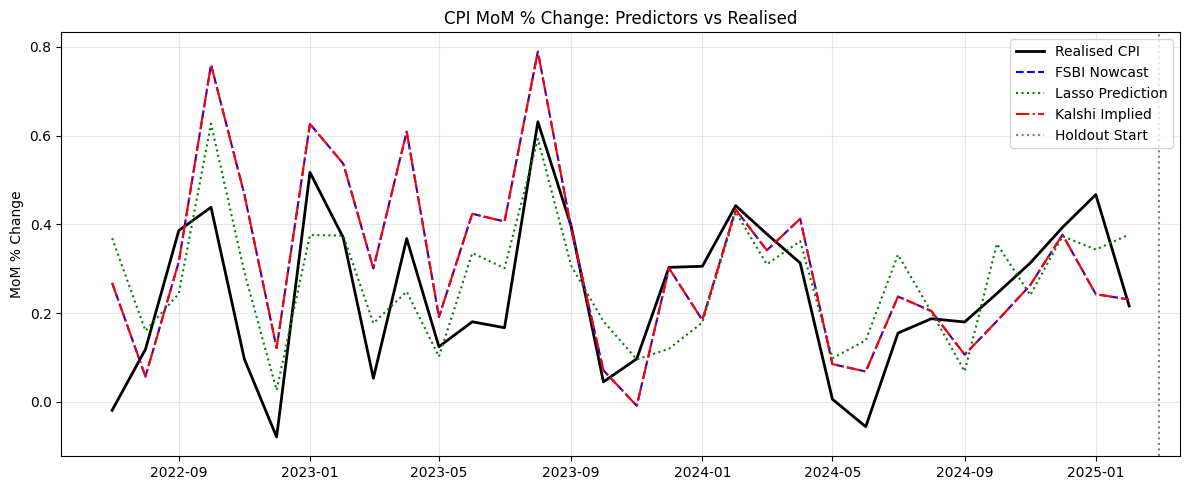

In [7]:
# -----------------------------------------------------------------------------
# 3. Predictor comparison plot
# -----------------------------------------------------------------------------
def plot_predictors(data, kalshi_series, model_pred_col="cpi_pred"):
    """
    Plot realised CPI, nowcast, model prediction, and Kalshi implied CPI.
    All series are MoM % changes.

    Parameters
    ----------
    data : pd.DataFrame
        Must contain `clev_cpi_first_print` (realised) and
        `clev_cpi_nowcast_fsbi` (nowcast).
    kalshi_series : pd.Series
        Kalshi implied CPI (monthly).
    model_pred_col : str
        Column name for the model prediction (default uses first print as
        a placeholder; replace with your actual model output).
    """
    fig, ax = plt.subplots(figsize=(12, 5))
    ax.plot(data.index, data["clev_cpi_first_print"], label="Realised CPI", color="black", linewidth=2)
    ax.plot(data.index, data["clev_cpi_nowcast_fsbi"], label="FSBI Nowcast", linestyle="--", color="blue")
    ax.plot(data.index, data[model_pred_col], label="Lasso Prediction", linestyle=":", color="green")
    ax.plot(kalshi_series.index, kalshi_series, label="Kalshi Implied", linestyle="-.", color="red")
    ax.axvline(HOLDOUT_START, color="gray", linestyle=":", label="Holdout Start")
    ax.set_title("CPI MoM % Change: Predictors vs Realised")
    ax.set_ylabel("MoM % Change")
    ax.legend()
    ax.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()


plot_predictors(data_pre, kalshi_series)

In [8]:
# -----------------------------------------------------------------------------
# 4. Helper: walk-forward backtester
# -----------------------------------------------------------------------------
def backtest_signal(signal, returns, cost=0.0005):
    """
    Simple backtest of a signal series.

    Parameters
    ----------
    signal : pd.Series
        Position taken at the end of each month (1 = long, -1 = short, 0 = flat).
    returns : pd.Series
        Monthly returns of the asset (or spread).
    cost : float
        Transaction cost per unit turnover (default 5 bps).

    Returns
    -------
    dict with keys: cum_return, sharpe, hit_rate, turnover, equity_curve
    """
    # Align
    df = pd.DataFrame({"signal": signal, "ret": returns}).dropna()
    if df.empty:
        return {}
    # Position is applied to next month's return
    df["pos"] = df["signal"].shift(1)
    df["gross"] = df["pos"] * df["ret"]
    # Turnover = absolute change in position
    df["turnover"] = df["pos"].diff().abs().fillna(0)
    df["net"] = df["gross"] - df["turnover"] * cost
    # Equity curve
    df["equity"] = (1 + df["net"]).cumprod()
    # Metrics
    ann_factor = 12  # monthly data
    sharpe = df["net"].mean() / df["net"].std() * np.sqrt(ann_factor) if df["net"].std() > 0 else np.nan
    hit = (df["net"] > 0).mean()
    return {
        "cum_return": df["equity"].iloc[-1] - 1,
        "sharpe": sharpe,
        "hit_rate": hit,
        "turnover": df["turnover"].mean(),
        "equity_curve": df["equity"],
        "net_returns": df["net"],
    }

"""
def block_bootstrap_pvalue(returns, block_size=3, n_boot=1000):
    
    # Block bootstrap p-value for mean return > 0.
    
    if len(returns) < block_size * 2:
        return np.nan
    n = len(returns)
    n_blocks = n // block_size
    boot_means = []
    for _ in range(n_boot):
        # sample blocks with replacement
        idx = np.random.choice(n_blocks, size=n_blocks, replace=True)
        boot_sample = np.concatenate([
            returns.iloc[i*block_size : (i+1)*block_size].values
            for i in idx
        ])
        boot_means.append(boot_sample.mean())
    boot_means = np.array(boot_means)
    return (boot_means <= 0).mean()  # one-sided p-value
"""

def block_bootstrap_pvalue(returns, block_size=3, n_boot=2000, seed=0):
    """
        Block bootstrap p-value for mean return > 0.
    """
    r = pd.Series(returns).dropna().values
    n = len(r)
    if n < block_size * 2:
        return np.nan
    rng = np.random.default_rng(seed)
    n_blocks = n // block_size
    starts = np.arange(0, n - block_size + 1)
    boot_means = np.empty(n_boot)
    for i in range(n_boot):
        idx = rng.choice(starts, size=n_blocks, replace=True)
        boot_means[i] = np.concatenate([r[s:s + block_size] for s in idx]).mean()
    return float((boot_means <= 0).mean())

def strategy_tips_long_only(data, threshold=THRESHOLD_TIPS):
    cpi_pred = data["cpi_pred"]
    breakeven = data["breakeven_10y"] / 12
    signal = ((cpi_pred - breakeven) > threshold).astype(int)
    return backtest_signal(signal, data["rbil_ret"])

In [12]:
# -----------------------------------------------------------------------------
# 5. Strategy implementations
# -----------------------------------------------------------------------------

# --- 5.1 Kalshi Directional ------------------------------------------------
"""
def strategy_kalshi_directional(data, kalshi_series, threshold=THRESHOLD_KALSHI):
    
    Kalshi betting strategy has yet to be made
"""

# --- 5.2 Ultrashort TIPS (Long Only) ---------------------------------------
def strategy_tips_long_only(data, threshold=THRESHOLD_TIPS):
    """
    Long RBIL when predicted CPI exceeds the breakeven.

    Signal = CPI_pred - Breakeven.
    If Signal > threshold  -> Long RBIL.
    Else flat.
    """
    cpi_pred = data["cpi_pred"]  # replace with model
    breakeven = data["breakeven_10y"] / 12 # convert avg annual expected inflation for the next 10 years to a monthly level.
    signal = (cpi_pred - breakeven) > threshold
    signal = signal.astype(int)  # 1 = long, 0 = flat
    # RBIL return (proxy: use STIP returns as a stand-in if RBIL not available)
    asset_ret = data["stip_ret"]
    return backtest_signal(signal, asset_ret)


# --- 5.3 TIPS Breakeven (Long/Short) ---------------------------------------
def strategy_tips_breakeven(data, threshold=THRESHOLD_TIPS, w=2.6/1.8):
    cpi_pred = data["cpi_pred"]
    breakeven = data["breakeven_10y"] / 12
    signal = pd.Series(0, index=data.index)
    signal[cpi_pred - breakeven >  threshold] =  1
    signal[cpi_pred - breakeven < -threshold] = -1
    spread_ret = data["stip_ret"] - w * data["shy_ret"]
    return backtest_signal(signal, spread_ret)

# --- 5.4 XLP/XLY Sector Rotation -------------------------------------------
def strategy_xlp_xly(data, public_estimate=kalshi_series, approach="A", threshold=THRESHOLD_XLP_XLY):
    """
    Long-only rotation between XLP (defensive) and XLY (cyclical).

    Approach A: |cpi_pred| > threshold           -> long XLP, else long XLY.
    Approach B: cpi_pred - public_estimate > 0   -> long XLP, else long XLY.
    """
    cpi_pred = data["cpi_pred"]

    if approach == "A":
        signal = pd.Series(-1, index=data.index)          # default: long XLY
        signal[cpi_pred.abs() > threshold] = 1            # long XLP
    elif approach == "B":
        signal = pd.Series(-1, index=data.index)
        signal[(cpi_pred - public_estimate) > 0] = 1
    else:
        raise ValueError("approach must be 'A' or 'B'")

    # backtest_signal computes pos * ret with pos = signal.shift(1).
    # We want pos * ret to equal:
    #   +xlp_ret when we're long XLP  (pos = +1)
    #   +xly_ret when we're long XLY  (pos = -1)
    # So ret must be:
    #   xlp_ret   when pos = +1
    #   -xly_ret  when pos = -1
    
    cond_ret = pd.Series(
        np.where(signal > 0, data["xlp_ret"], -data["xly_ret"]),
        index=data.index,
    )
    return backtest_signal(signal, cond_ret)
    


# --- 5.5 Bitcoin (not presently viable) ------------------------------------
def strategy_bitcoin(data):
    """
    Placeholder: Bitcoin is not a reliable inflation hedge.
    """
    surprise = data["clev_cpi_first_print"] - data["clev_cpi_nowcast_fsbi"]
    signal = (surprise > 0).astype(int)
    return backtest_signal(signal, data["btc_ret"])


# --- 5.6 Volatility Trade (not presently viable) ---------------------------
def strategy_volatility(data):
    """
    Placeholder: short volatility around CPI releases is not viable due to
    the volatility crush.  Kept for completeness.
    """
    signal = pd.Series(-1, index=data.index)   # always short VXX
    return backtest_signal(signal, data["vxx_ret"])

In [13]:
# =============================================================================
# Diagnostics for TIPS strategies
# =============================================================================
import pandas as pd
import numpy as np

# --- Build the signal components once ---
monthly_be = data_pre["breakeven_10y"] / 12
diff = (data_pre["cpi_pred"] - monthly_be).rename("diff")

stip = data_pre["stip_ret"].dropna()
shy  = data_pre["shy_ret"].dropna()

print("=" * 70)
print("SIGNAL: cpi_pred - breakeven_10y / 12")
print("=" * 70)
print(diff.dropna().describe().round(4))
print()

t = THRESHOLD_TIPS
n_long  = (diff >  t).sum()
n_short = (diff < -t).sum()
n_flat  = (diff.abs() <= t).sum()
print(f"Threshold: {t}")
print(f"  Long  signal (diff >  +{t}): {n_long:3d} months")
print(f"  Short signal (diff <  -{t}): {n_short:3d} months")
print(f"  Flat  signal (|diff| <= {t}): {n_flat:3d} months")
print()

# --- Underlying asset behavior (the "do we even have a spread?" question) ---
print("=" * 70)
print("UNDERLYING ASSETS")
print("=" * 70)
print(f"STIP: mean {stip.mean():.4f},  std {stip.std():.4f},  cum {(1+stip).prod()-1:.2%}")
print(f"SHY:  mean {shy.mean():.4f},  std {shy.std():.4f},  cum {(1+shy).prod()-1:.2%}")

spread_eq = (stip - shy).dropna()
print(f"\nSTIP - SHY (equal weight):")
print(f"  mean {spread_eq.mean():.4f},  std {spread_eq.std():.4f},  "
      f"cum {(1+spread_eq).prod()-1:.2%}")
print(f"  corr with STIP: {spread_eq.corr(stip):.3f}")
print(f"  corr with SHY:  {spread_eq.corr(shy):.3f}")

# Duration-weighted: STIP - 1.44 * SHY
d_stip, d_shy = 2.6, 1.8
w = d_stip / d_shy
spread_dur = (stip - w * shy).dropna()
print(f"\nSTIP - {w:.2f} * SHY (duration-weighted):")
print(f"  mean {spread_dur.mean():.4f},  std {spread_dur.std():.4f},  "
      f"cum {(1+spread_dur).prod()-1:.2%}")
print(f"  corr with STIP: {spread_dur.corr(stip):.3f}")
print(f"  corr with SHY:  {spread_dur.corr(shy):.3f}")
print()

# --- Signal -> next-period return correlation ---
print("=" * 70)
print("SIGNAL -> NEXT-MONTH RETURN CORRELATION")
print("=" * 70)

def corr_signal_next(sig, ret, label):
    aligned = pd.concat([sig.shift(1).rename("s"), ret.rename("r")], axis=1).dropna()
    c = aligned["s"].corr(aligned["r"])
    n = len(aligned)
    print(f"  {label:40s}  corr = {c:+.3f}  (n = {n})")
    return c

# Long-only signal (+1 / 0)
long_sig = (diff > t).astype(int)
corr_signal_next(long_sig, stip, "Long-only: signal vs STIP next-month")

# Long-short signal (+1 / -1 / 0)
ls_sig = pd.Series(0, index=diff.index)
ls_sig[diff >  t] = 1
ls_sig[diff < -t] = -1
corr_signal_next(ls_sig, spread_eq,  "Long-short: signal vs (STIP-SHY)")
corr_signal_next(ls_sig, spread_dur, f"Long-short: signal vs (STIP-{w:.2f}SHY)")
print()

# --- Benchmarks: what if you were just always long? ---
print("=" * 70)
print("BENCHMARKS (what the strategies are compared to)")
print("=" * 70)
print(f"  Always long STIP:           {(1+stip).prod()-1:+.2%}")
print(f"  Always long (STIP-SHY):     {(1+spread_eq).prod()-1:+.2%}")
print(f"  Always long (STIP-{w:.2f}SHY): {(1+spread_dur).prod()-1:+.2%}")
print(f"  Always short VXX (5.6 cmp): {(1+data_pre['vxx_ret'].dropna()).prod()-1:+.2%}")
print()

# --- What fraction of the spread move happens in signal-on months? ---
print("=" * 70)
print("CONDITIONAL RETURNS (return when signal says what)")
print("=" * 70)
def cond_stats(sig, ret, label):
    aligned = pd.concat([sig.shift(1).rename("s"), ret.rename("r")], axis=1).dropna()
    on  = aligned.loc[aligned["s"] >  0, "r"]
    off = aligned.loc[aligned["s"] <  0, "r"]
    zer = aligned.loc[aligned["s"] == 0, "r"]
    print(f"  {label}")
    print(f"    signal=+1: n={len(on):3d}  mean={on.mean():+.4f}" if len(on) else "    signal=+1: n=0")
    print(f"    signal=-1: n={len(off):3d}  mean={off.mean():+.4f}" if len(off) else "    signal=-1: n=0")
    print(f"    signal= 0: n={len(zer):3d}  mean={zer.mean():+.4f}" if len(zer) else "    signal= 0: n=0")

cond_stats(long_sig, stip,        "Long-only vs STIP")
cond_stats(ls_sig,   spread_eq,   "Long-short vs STIP-SHY")
cond_stats(ls_sig,   spread_dur,  f"Long-short vs STIP-{w:.2f}SHY")

SIGNAL: cpi_pred - breakeven_10y / 12
count    32.0000
mean      0.0809
std       0.1386
min      -0.1620
25%      -0.0254
50%       0.1020
75%       0.1672
max       0.4275
Name: diff, dtype: float64

Threshold: 0.1
  Long  signal (diff >  +0.1):  16 months
  Short signal (diff <  -0.1):   2 months
  Flat  signal (|diff| <= 0.1):  14 months

UNDERLYING ASSETS
STIP: mean 0.0031,  std 0.0095,  cum 10.26%
SHY:  mean 0.0026,  std 0.0065,  cum 8.45%

STIP - SHY (equal weight):
  mean 0.0005,  std 0.0055,  cum 1.71%
  corr with STIP: 0.749
  corr with SHY:  0.249

STIP - 1.44 * SHY (duration-weighted):
  mean -0.0006,  std 0.0056,  cum -1.93%
  corr with STIP: 0.312
  corr with SHY:  -0.275

SIGNAL -> NEXT-MONTH RETURN CORRELATION
  Long-only: signal vs STIP next-month      corr = +0.132  (n = 31)
  Long-short: signal vs (STIP-SHY)          corr = +0.087  (n = 31)
  Long-short: signal vs (STIP-1.44SHY)      corr = +0.029  (n = 31)

BENCHMARKS (what the strategies are compared to)
  Always l


Strategy Backtest Summary (pre-holdout)
            Strategy Cum Return Sharpe Hit Rate Avg Turnover
      TIPS Long Only      5.15%   0.96   34.38%         0.44
      TIPS Breakeven     -1.93%  -0.78   18.75%         0.56
XLP/XLY (Approach A)     50.79%   1.00   53.12%         0.88
XLP/XLY (Approach B)     18.98%   0.43   53.12%         0.50


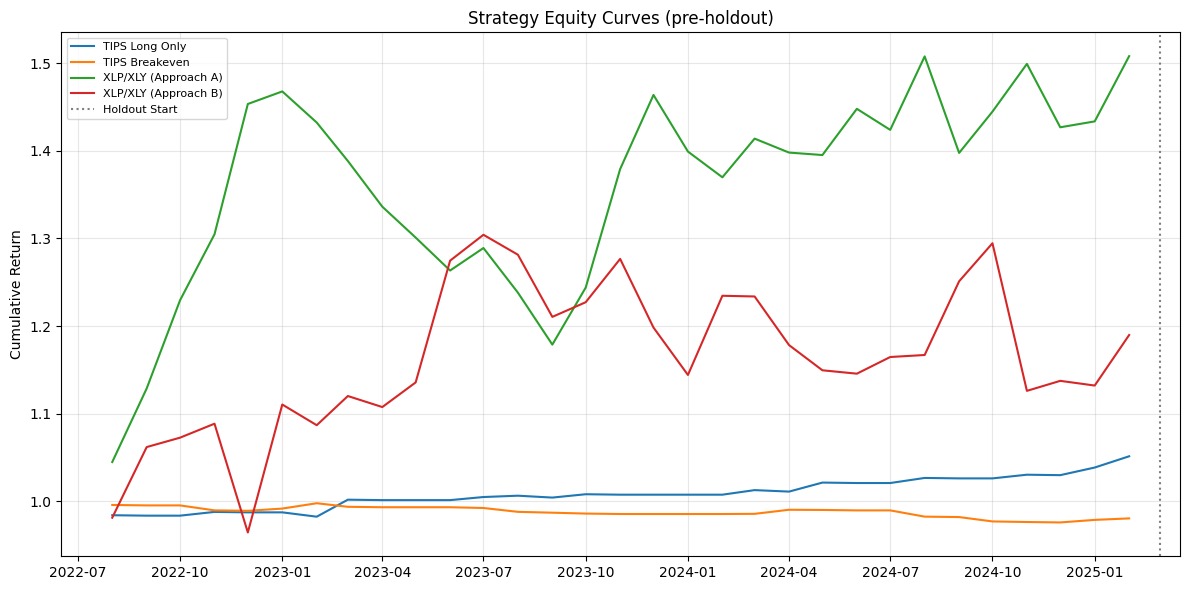

In [14]:
# -----------------------------------------------------------------------------
# 6. Run backtests (pre-holdout only)
# -----------------------------------------------------------------------------
strategies = {
    # "Kalshi Directional": strategy_kalshi_directional(data_pre, kalshi_series),
    "TIPS Long Only": strategy_tips_long_only(data_pre),
    "TIPS Breakeven": strategy_tips_breakeven(data_pre),
    "XLP/XLY (Approach A)": strategy_xlp_xly(data_pre, approach="A"),
    "XLP/XLY (Approach B)": strategy_xlp_xly(data_pre, approach="B"),
    # "Bitcoin (not viable)": strategy_bitcoin(data_pre),
    # "Volatility (not viable)": strategy_volatility(data_pre),
}

# Print summary table
summary = []
for name, res in strategies.items():
    if res:
        summary.append({
            "Strategy": name,
            "Cum Return": f"{res['cum_return']:.2%}",
            "Sharpe": f"{res['sharpe']:.2f}",
            "Hit Rate": f"{res['hit_rate']:.2%}",
            "Avg Turnover": f"{res['turnover']:.2f}",
        })
summary_df = pd.DataFrame(summary)
print("\n" + "="*60)
print("Strategy Backtest Summary (pre-holdout)")
print("="*60)
print(summary_df.to_string(index=False))

# Optional: plot equity curves
fig, ax = plt.subplots(figsize=(12, 6))
for name, res in strategies.items():
    if res and "equity_curve" in res:
        ax.plot(res["equity_curve"].index, res["equity_curve"], label=name)
ax.axvline(HOLDOUT_START, color="gray", linestyle=":", label="Holdout Start")
ax.set_title("Strategy Equity Curves (pre-holdout)")
ax.set_ylabel("Cumulative Return")
ax.legend(loc="upper left", fontsize=8)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [15]:
# -----------------------------------------------------------------------------
# 7. Block-bootstrap p-values (optional)
# -----------------------------------------------------------------------------
print("\n" + "="*60)
print("Block-bootstrap p-values (H0: mean return <= 0)")
print("="*60)
for name, res in strategies.items():
    if res and "net_returns" in res:
        pval = block_bootstrap_pvalue(res["net_returns"])
        print(f"{name:30s}  p = {pval:.3f}")


Block-bootstrap p-values (H0: mean return <= 0)
TIPS Long Only                  p = 0.011
TIPS Breakeven                  p = 0.893
XLP/XLY (Approach A)            p = 0.116
XLP/XLY (Approach B)            p = 0.219


In [ ]:
# -----------------------------------------------------------------------------
# 8. Notes on strategy validity
# -----------------------------------------------------------------------------
print("\n" + "="*60)
print("Notes on strategy validity (based on research note)")
print("="*60)
print("""
- Kalshi Directional, Ultrashort TIPS, TIPS Breakeven, and XLP/XLY rotation
  are the four strategies that are *potentially valid* according to the
  preliminary research.  They rely on a CPI prediction that beats the
  nowcast/Kalshi implied, and on the economic mechanisms described in the
  associated literature.

- Bitcoin and Volatility Trade are flagged as *likely invalid*:
  * Bitcoin has not shown a consistent inflation-hedge relationship
    (especially post-COVID and after institutional adoption).
  * The volatility crush around CPI releases makes a naive short-vol
    strategy unprofitable; only extreme tail events would justify it,
    and there is insufficient data to support such a strategy.

These prototypes are deliberately simple.  Before any live trading you
should:
  1. Refine the CPI prediction model (e.g. use the Sparse OLS / ARIMAX
     from your Phase 3 notebook).
  2. Properly calibrate the Kalshi implied CPI (e.g. fit a distribution
     across all strikes, not just the highest-volume market).
  3. Add realistic transaction costs, borrow costs, and slippage.
  4. Validate on the holdout set *only once* after locking the model.
""")


Notes on strategy validity (based on research note)

- Kalshi Directional, Ultrashort TIPS, TIPS Breakeven, and XLP/XLY rotation
  are the four strategies that are *potentially valid* according to the
  preliminary research.  They rely on a CPI prediction that beats the
  nowcast/Kalshi implied, and on the economic mechanisms described in the
  associated literature.

- Bitcoin and Volatility Trade are flagged as *likely invalid*:
  * Bitcoin has not shown a consistent inflation-hedge relationship
    (especially post-COVID and after institutional adoption).
  * The volatility crush around CPI releases makes a naive short-vol
    strategy unprofitable; only extreme tail events would justify it,
    and there is insufficient data to support such a strategy.

These prototypes are deliberately simple.  Before any live trading you
should:
  1. Refine the CPI prediction model (e.g. use the Sparse OLS / ARIMAX
     from your Phase 3 notebook).
  2. Properly calibrate the Kalshi implied CPI 